# Steam 게임 추천 프로젝트 — 원본 데이터 EDA

이 노트북은 `MLTP_proposal_team6 (1).docx`의 리눅스 지원 Steam 게임 추천 기획안을 바탕으로 원본 데이터의 구조·품질·연결 가능성을 분석합니다. **모델 학습이나 최종 전처리 파일 생성은 하지 않습니다.** 실행 결과와 그래프를 확인한 뒤 팀에서 필터링·평가 기준을 결정합니다.

## 데이터별 역할

| 구분 | 원본 파일 | 기획안에서의 역할 | EDA에서 확인할 내용 |
|---|---|---|---|
| A | `recommendations.csv` | 사용자–게임 추천 여부·리뷰 날짜·플레이 시간: 아이템 기반 KNN 학습 | 리뷰 수, 결측, 날짜, 긍정 비율, 사용자·게임별 이력, 중복 |
| A | `games.csv` | 게임 제목과 공식 Linux 지원 여부, 공통 게임 목록 | Linux 지원 비율, ID 중복, B·C와 겹침 |
| A | `games_metadata.json` | 게임 설명·태그: 콘텐츠 기반 추천 보조 | 설명·태그 빈 값과 게임 ID 연결 |
| B | `games_march2025_cleaned.csv` | 설명·장르·태그로 TF-IDF 콘텐츠 보강 | ID 중복·결측, A 대비 콘텐츠 추가 가능성 |
| C | `australian_user_reviews.json` | 외부 사용자 취향 입력 및 숨긴 정답 구성 | 날짜, 긍정 리뷰, A Linux 게임과 겹침, 사용자별 리뷰 수 |

게임은 Steam App ID로 연결하며 A와 C 사용자 ID는 연결하지 않습니다. 팀원 EDA에서는 **B와 C 이름이 반대**이므로 공유할 때 파일명으로 확인하세요. 기획안의 2015/2016 날짜 분리는 중복 가능성을 줄이기 위한 예시이며 사람이나 편집된 리뷰의 독립성을 보장하지 않습니다. C가 실제 Linux 사용자라는 보장도 없습니다. 게임 메타데이터의 수집 시점은 리뷰 시점과 다릅니다.

## 사용법
1. Google Drive에 `MyDrive/steam_preprocessing/data/`를 만들고 아래 경로에 원본 파일을 업로드합니다. 이 노트북을 Colab에 업로드해 열고 셀을 위에서부터 실행합니다.
2. 큰 A 리뷰는 Colab 임시 디스크를 이용해 집계하므로 오래 걸릴 수 있습니다. 런타임 디스크 공간이 부족하면 실패할 수 있습니다. 원본 파일은 수정하지 않습니다.
3. `FULL_DATA = True`는 전체를 분석합니다. `False`는 A 리뷰 파일의 앞부분만 읽는 시험이며 무작위 표본이 아니므로 최종 결론에 사용하지 마세요.

```text
MyDrive/steam_preprocessing/data/
  A/games.csv
  A/games_metadata.json
  A/recommendations.csv
  B/games_march2025_cleaned.csv
  C/australian_user_reviews.json
```
원본: [A](https://www.kaggle.com/datasets/antonkozyriev/game-recommendations-on-steam), [B](https://www.kaggle.com/datasets/artermiloff/steam-games-dataset), [C](https://www.kaggle.com/datasets/pypiahmad/steam-video-game-and-bundle-data). 공유·재배포 전 각 출처의 라이선스를 확인하세요.


In [25]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [26]:
%pip -q install duckdb pandas matplotlib


In [27]:
from pathlib import Path
import pandas as pd, numpy as np, matplotlib.pyplot as plt
import duckdb, json, ast, re, html, gzip, time
from IPython.display import display

ROOT = Path('/content/drive/MyDrive/steam_preprocessing/data')  # 다른 위치면 수정
FULL_DATA = True  # 전체 분석: True, A 앞부분 100만 행 시험: False
paths = {'A_games': ROOT/'A/games.csv', 'A_metadata': ROOT/'A/games_metadata.json',
         'A_reviews': ROOT/'A/recommendations.csv', 'B_games': ROOT/'B/games_march2025_cleaned.csv',
         'C_reviews': ROOT/'C/australian_user_reviews.json'}
for name, path in paths.items():
    print(f"{name}: {'OK' if path.is_file() else '없음'} | {path} | {path.stat().st_size/1e6:.1f} MB" if path.is_file() else f'{name}: 없음 | {path}')
if not all(p.is_file() for p in paths.values()):
    raise FileNotFoundError('없음으로 표시된 파일 경로를 확인하세요.')
print('분석 범위:', '전체 원본' if FULL_DATA else 'A 리뷰 앞부분 100만 행만 — 최종 결과 아님')


A_games: OK | /content/drive/MyDrive/steam_preprocessing/data/A/games.csv | 4.9 MB
A_metadata: OK | /content/drive/MyDrive/steam_preprocessing/data/A/games_metadata.json | 17.5 MB
A_reviews: OK | /content/drive/MyDrive/steam_preprocessing/data/A/recommendations.csv | 824.2 MB
B_games: OK | /content/drive/MyDrive/steam_preprocessing/data/B/games_march2025_cleaned.csv | 468.6 MB
C_reviews: OK | /content/drive/MyDrive/steam_preprocessing/data/C/australian_user_reviews.json | 26.3 MB
분석 범위: 전체 원본


## 1. 원본 구조와 게임 메타데이터
각 파일의 크기, 열, 빈 값, 중복을 확인합니다. ID는 문자열로 보존하고 A·B를 게임 ID로 연결합니다. 빈 문자열과 `[]`, `{}`도 빈 콘텐츠로 취급합니다.



A games: columns, null counts


,column,nulls
0,app_id,0
1,title,0
2,date_release,0
3,win,0
4,mac,0
5,linux,0
6,rating,0
7,positive_ratio,0
8,user_reviews,0
9,price_final,0



B selected columns and nulls


,column,nulls
0,appid,0
1,name,0
2,detailed_description,197
3,about_the_game,220
4,short_description,120
5,linux,0
6,genres,0
7,tags,0



ID quality (rows; duplicate IDs exclude missing)


,dataset,rows,missing_or_invalid_id,duplicate_id_rows
0,A games,50872,0,0
1,B games,89618,0,0


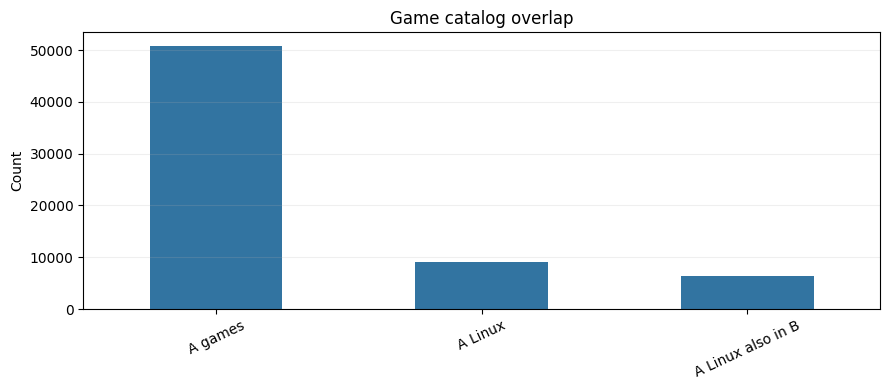

Linux 기준은 A games.csv의 linux 열입니다. 파일 간 OS 정보 불일치는 아래에서 확인합니다.


In [28]:
import csv

def clean_id(s):
    s = s.astype('string').str.strip().str.replace(r'\.0$', '', regex=True)
    return s.where(s.str.fullmatch(r'\d+', na=False))
def has_text(v):
    if v is None or (not isinstance(v, (list,dict)) and pd.isna(v)):
        return False
    if isinstance(v, (list,dict)):
        return len(v) > 0
    s = html.unescape(re.sub(r'<[^>]*>', ' ', str(v))).strip()
    return s.lower() not in ('', '[]', '{}', 'null', 'nan', 'none')
def is_true(s):
    return s.astype('string').str.strip().str.lower().isin(['true','1','yes'])
def show(label, obj):
    print('\n' + label)
    display(obj)
def plot_counts(data, title, ylabel='Count'):
    fig, ax = plt.subplots(figsize=(9,4))
    pd.Series(data).plot.bar(ax=ax, color='#3274a1')
    ax.set_title(title); ax.set_ylabel(ylabel); ax.tick_params(axis='x', rotation=25)
    ax.grid(axis='y', alpha=.2); plt.tight_layout(); plt.show()

a = pd.read_csv(paths['A_games'], dtype='string')
# csv.QUOTE_NONE(3) 혹은 duckdb를 우회책으로 사용하여 따옴표 파싱 에러 방지
try:
    b = pd.read_csv(paths['B_games'], dtype='string', usecols=lambda c: c in ['appid','name','linux','short_description','detailed_description','about_the_game','genres','tags'])
except Exception:
    # 에러가 발생하는 경우 duckdb를 이용해 안전하게 데이터프레임으로 변환합니다.
    print('Pandas 기본 파서에서 에러가 발생하여 DuckDB를 통해 B 데이터를 로드합니다.')
    b_path = str(paths['B_games']).replace("'", "''")
    b = duckdb.query(f"SELECT appid, name, linux, short_description, detailed_description, about_the_game, genres, tags FROM read_csv('{b_path}', all_varchar=True, ignore_errors=true)").df().astype('string')

show('A games: columns, null counts', pd.DataFrame({'column':a.columns, 'nulls':a.isna().sum().values}))
show('B selected columns and nulls', pd.DataFrame({'column':b.columns, 'nulls':b.isna().sum().values}))
a['id'] = clean_id(a['app_id']); b['id'] = clean_id(b['appid'])
show('ID quality (rows; duplicate IDs exclude missing)', pd.DataFrame([
    {'dataset':n, 'rows':len(d), 'missing_or_invalid_id':int(d.id.isna().sum()), 'duplicate_id_rows':int(d.id.dropna().duplicated().sum())}
    for n,d in [('A games',a),('B games',b)]]))
a1 = a.dropna(subset=['id']).drop_duplicates('id').copy()
b1 = b.dropna(subset=['id']).drop_duplicates('id').copy()
linux_ids = set(a1.loc[is_true(a1.linux), 'id']); a_ids=set(a1.id); b_ids=set(b1.id)
plot_counts({'A games':len(a_ids), 'A Linux':len(linux_ids), 'A Linux also in B':len(linux_ids & b_ids)}, 'Game catalog overlap')
print('Linux 기준은 A games.csv의 linux 열입니다. 파일 간 OS 정보 불일치는 아래에서 확인합니다.')

In [29]:
def json_records(path):
    # A metadata can contain JSON objects with unescaped newlines inside strings.
    raw = path.read_text(encoding='utf-8-sig')
    decoder = json.JSONDecoder(strict=False); pos = 0
    while pos < len(raw):
        while pos < len(raw) and raw[pos].isspace(): pos += 1
        if pos >= len(raw): break
        obj, pos = decoder.raw_decode(raw, pos)
        if isinstance(obj, list): yield from obj
        else: yield obj

meta=[]
for obj in json_records(paths['A_metadata']):
    meta.append({'id':str(obj.get('app_id',obj.get('appid',''))),
                 'a_text':any(has_text(obj.get(k)) for k in ['description','short_description','genres','tags'])})
meta=pd.DataFrame(meta); meta['id']=clean_id(meta.id)
print('A metadata rows:',len(meta),'| invalid IDs:',meta.id.isna().sum(),'| duplicate IDs:',meta.id.dropna().duplicated().sum())
meta=meta.dropna(subset=['id']).drop_duplicates('id')
fields=[c for c in ['short_description','detailed_description','about_the_game','genres','tags'] if c in b1.columns]
if not fields: raise ValueError('B의 설명·장르·태그 열을 찾지 못했습니다. 실제 헤더를 확인하세요.')
b1['b_text']=b1[fields].apply(lambda col: col.map(has_text)).any(axis=1)
joined=a1[a1.id.isin(linux_ids)][['id','linux']].merge(meta,on='id',how='left').merge(b1[['id','linux','b_text']].rename(columns={'linux':'b_linux'}),on='id',how='left')
joined['a_text']=joined.a_text.fillna(False).astype(bool); joined['b_text']=joined.b_text.fillna(False).astype(bool)
print('A Linux 게임에서 A/B 콘텐츠 보유 조합:')
display(pd.crosstab(joined.a_text, joined.b_text, rownames=['A content'], colnames=['B content']))
print('B로 콘텐츠 보강 가능한 A 콘텐츠 빈 게임:', int((~joined.a_text & joined.b_text).sum()))
if 'b_linux' in joined:
    comparable=joined.b_linux.notna() & joined.b_linux.str.strip().ne('')
    print('A Linux인 게임 중 B OS 값 확인 가능:',int(comparable.sum()),'| B에서 Linux 미지원으로 표시:',int((comparable & ~is_true(joined.b_linux)).sum()))
print('이 수치는 콘텐츠 존재 여부만 나타내며 품질이나 최종 추천 후보 수를 보장하지 않습니다.')


A metadata rows: 50872 | invalid IDs: 0 | duplicate IDs: 0
A Linux 게임에서 A/B 콘텐츠 보유 조합:


/tmp/ipykernel_2368/457120748.py:23: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  joined['a_text']=joined.a_text.fillna(False).astype(bool); joined['b_text']=joined.b_text.fillna(False).astype(bool)


B content,False,True
A content,,
False,56,126
True,2545,6314


B로 콘텐츠 보강 가능한 A 콘텐츠 빈 게임: 126
A Linux인 게임 중 B OS 값 확인 가능: 6440 | B에서 Linux 미지원으로 표시: 58
이 수치는 콘텐츠 존재 여부만 나타내며 품질이나 최종 추천 후보 수를 보장하지 않습니다.


## 2. A 원본 리뷰 EDA
DuckDB가 A CSV를 Colab 임시 디스크의 분석용 테이블로 읽습니다. 원본은 변경하지 않습니다. 사용자별·게임별 분포는 긍정 리뷰 기준이며, 중복 사용자–게임 쌍은 별도로 확인합니다. 긍정 비율은 추천 여부가 확인된 리뷰를 분모로 사용합니다.


A 리뷰 로딩 중: 수 분 이상 걸릴 수 있습니다...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

로딩 완료 (초): 43.9


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))


A review summary


,0
rows,16819477
users,8226623
games,2827
missing_user,0
missing_game,0
missing_or_invalid_date,0
first_date,2010-10-15 00:00:00
last_date,2022-12-31 00:00:00
positive,14447691
negative,2371786


긍정 리뷰 비율 (추천 여부 확인 건 기준): 85.90%


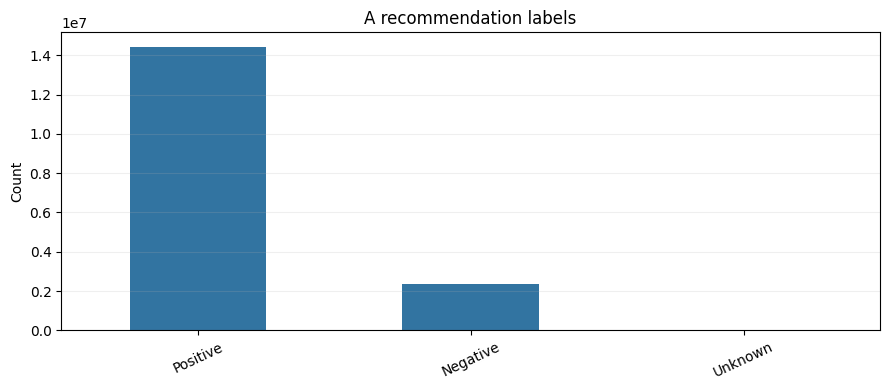

In [30]:
con=duckdb.connect('/content/steam_eda_temp.duckdb')
con.execute("SET threads=2")
con.execute("SET memory_limit='3GB'")
con.execute("SET temp_directory='/content/steam_eda_tmp'")
csv_path=str(paths['A_reviews']).replace("'", "''")
limit='' if FULL_DATA else ' LIMIT 1000000'
print('A 리뷰 로딩 중: 수 분 이상 걸릴 수 있습니다...')
start=time.time()
con.execute(f"""CREATE OR REPLACE TABLE reviews AS
 SELECT CAST(app_id AS VARCHAR) app_id, CAST(user_id AS VARCHAR) user_id,
        TRY_CAST(date AS DATE) review_date, lower(trim(CAST(is_recommended AS VARCHAR))) recommended,
        TRY_CAST(hours AS DOUBLE) "hours"
 FROM read_csv('{csv_path}', header=true, all_varchar=true, ignore_errors=true){limit}""")
print('로딩 완료 (초):',round(time.time()-start,1))
summary=con.sql("""SELECT count(*) AS "rows", count(DISTINCT user_id) users, count(DISTINCT app_id) games,
 count(*) FILTER (WHERE user_id IS NULL OR trim(user_id)='') missing_user,
 count(*) FILTER (WHERE app_id IS NULL OR trim(app_id)='') missing_game,
 count(*) FILTER (WHERE review_date IS NULL) missing_or_invalid_date,
 min(review_date) first_date, max(review_date) last_date,
 count(*) FILTER (WHERE recommended IN ('true','1','yes')) positive,
 count(*) FILTER (WHERE recommended IN ('false','0','no')) negative,
 count(*) FILTER (WHERE recommended IS NULL OR recommended NOT IN ('true','1','yes','false','0','no')) unknown_recommendation,
 count(*) FILTER (WHERE "hours" IS NULL) missing_hours,
 count(*) FILTER (WHERE "hours" < 0) negative_hours FROM reviews""").df()
show('A review summary',summary.T)
v=summary.iloc[0]; denom=v.positive+v.negative
print('긍정 리뷰 비율 (추천 여부 확인 건 기준):',f'{100*v.positive/denom:.2f}%' if denom else '계산 불가')
plot_counts({'Positive':int(v.positive),'Negative':int(v.negative),'Unknown':int(v.unknown_recommendation)}, 'A recommendation labels')

중복과 이력 분포 집계 중...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))


Duplicate user-game pairs


,duplicate_groups,extra_rows
0,5,5.0


,year,reviews,positive
0,2010,3384,3295
1,2011,17463,16882
2,2012,28051,27028
3,2013,118132,110786
4,2014,408156,365354
5,2015,526391,438171
6,2016,816028,664006
7,2017,997323,796574
8,2018,974350,780760
9,2019,1561151,1364405


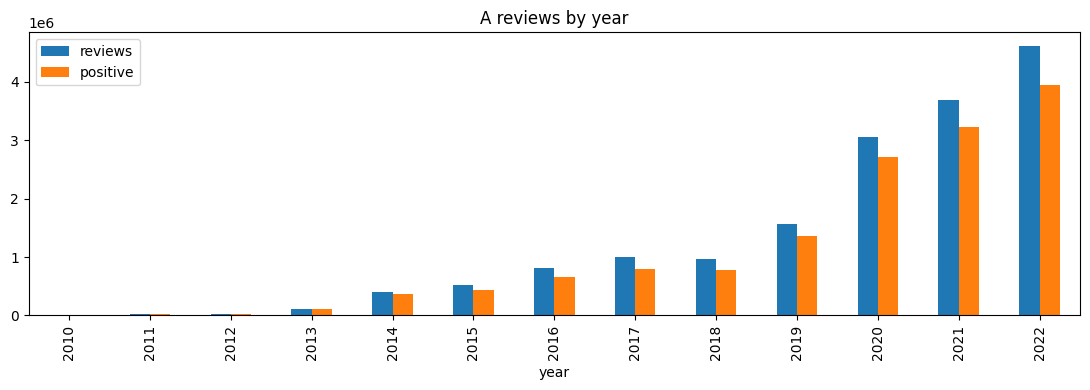

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))


A positive review rows per user (not deduplicated)


,0
users_with_positive,7483112.0
median,1.0
p90,4.0
max,446.0
one_positive,4930618.0
at_least_3,1292799.0



A most positively reviewed games (all OS; duplicate rows included)


,title,app_id,n
0,Rust,252490,210537
1,Counter-Strike: Global Offensive,730,152100
2,Wallpaper Engine,431960,150548
3,Fallout 4,377160,119610
4,No Man's Sky,275850,119249
5,Red Dead Redemption 2,1174180,115176
6,Arma 3,107410,109523
7,Borderlands 2,49520,109422
8,Sea of Thieves 2023 Edition,1172620,107173
9,Path of Exile,238960,104155


In [31]:
print('중복과 이력 분포 집계 중...')
dups=con.sql("""SELECT count(*) duplicate_groups, coalesce(sum(n-1),0) extra_rows
FROM (SELECT user_id, app_id, count(*) n FROM reviews
 WHERE user_id IS NOT NULL AND app_id IS NOT NULL GROUP BY user_id, app_id HAVING count(*) > 1)""").df()
show('Duplicate user-game pairs',dups)
yearly=con.sql("""SELECT year(review_date) AS "year", count(*) reviews,
 count(*) FILTER (WHERE recommended IN ('true','1','yes')) positive FROM reviews
 WHERE review_date IS NOT NULL GROUP BY 1 ORDER BY 1""").df()
display(yearly)
if len(yearly):
    yearly.set_index('year')[['reviews','positive']].plot.bar(figsize=(11,4), title='A reviews by year'); plt.tight_layout(); plt.show()
dist=con.sql("""WITH counts AS (SELECT user_id, count(*) n FROM reviews WHERE user_id IS NOT NULL
 AND recommended IN ('true','1','yes') GROUP BY user_id)
 SELECT count(*) users_with_positive, median(n) median, quantile_cont(n,0.9) p90,
 max(n) max, count(*) FILTER (WHERE n=1) one_positive,
 count(*) FILTER (WHERE n>=3) at_least_3 FROM counts""").df()
show('A positive review rows per user (not deduplicated)',dist.T)
items=con.sql("""SELECT app_id, count(*) n FROM reviews WHERE recommended IN ('true','1','yes')
 AND app_id IS NOT NULL GROUP BY app_id ORDER BY n DESC LIMIT 10""").df()
items['app_id']=clean_id(items.app_id); items=items.merge(a1[['id','title']],left_on='app_id',right_on='id',how='left')
show('A most positively reviewed games (all OS; duplicate rows included)',items[['title','app_id','n']])

## 3. C 외부 리뷰의 품질과 평가 가능성
C는 Python 딕셔너리 형식의 원본을 안전하게 파싱합니다. 연도가 없는 날짜는 추측하지 않습니다. 아래 2015년 이전·긍정·A Linux 겹침 집계는 기획안에 제시된 **후보 조건을 탐색**하는 것으로 최종 평가 데이터 생성이 아닙니다.


C profile rows: 25799 | review rows: 59305 | users: 25458
C missing user IDs: 0 | invalid game IDs: 0
C missing year: 10119 | invalid date: 10119
C duplicate user-game rows (extra rows): 874
C recommend values: {'true': 52473, 'false': 6832}


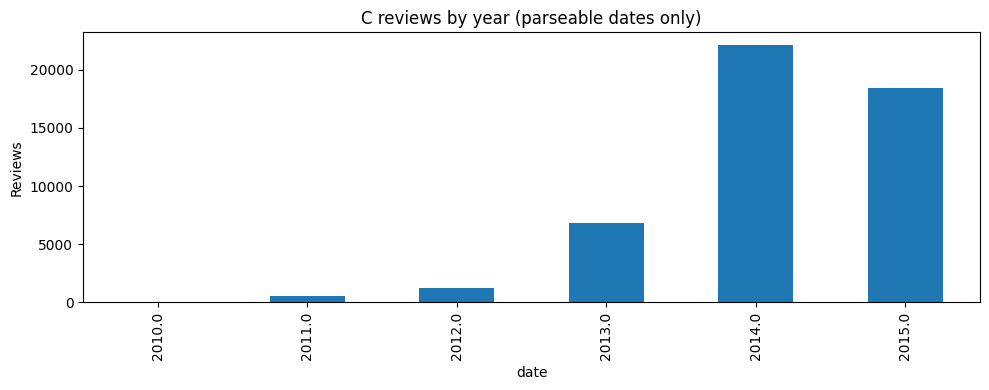


C overlap with A Linux under example date/positive conditions


,0
positive_dated_reviews_through_2015,44182
matching_A_linux_review_rows,24693
matching_distinct_games,761
users_with_1plus_games,15822
users_with_2plus_games,4992
users_with_3plus_games,2039


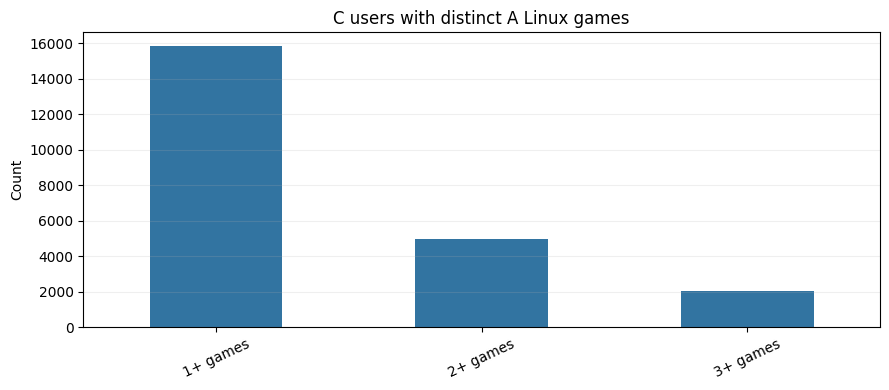

위 사용자 수는 A 학습 필터와 C 중복 해결 전의 탐색 수치입니다.


In [32]:
c_rows=[]; profiles=0
with paths['C_reviews'].open(encoding='utf-8-sig') as f:
    for line_no,line in enumerate(f,1):
        if not line.strip(): continue
        try: obj=ast.literal_eval(line)
        except (ValueError,SyntaxError) as e: raise ValueError(f'C line {line_no}: parse failed') from e
        profiles+=1
        for review in obj.get('reviews',[]):
            c_rows.append((str(obj.get('user_id','')).strip(),str(review.get('item_id','')).strip(),
                           str(review.get('posted','')),str(review.get('recommend','')).lower()))
c=pd.DataFrame(c_rows,columns=['user_id','app_id','posted','recommend'])
c['app_id']=clean_id(c.app_id)
c['has_year']=c.posted.str.contains(r'\b(?:19|20)\d{2}\b',regex=True)
c['date']=pd.to_datetime(c.posted.str.replace(r'^Posted\s+', '',regex=True).str.rstrip('.'),format='%B %d, %Y',errors='coerce')
c['positive']=c.recommend.isin(['true','1','yes'])
print('C profile rows:',profiles,'| review rows:',len(c),'| users:',c.user_id.replace('',pd.NA).nunique())
print('C missing user IDs:',int(c.user_id.eq('').sum()),'| invalid game IDs:',int(c.app_id.isna().sum()))
print('C missing year:',int((~c.has_year).sum()),'| invalid date:',int(c.date.isna().sum()))
print('C duplicate user-game rows (extra rows):',int(c[c.user_id.ne('') & c.app_id.notna()].duplicated(['user_id','app_id']).sum()))
print('C recommend values:',c.recommend.value_counts(dropna=False).to_dict())
cy=c.dropna(subset=['date']).groupby(c.date.dt.year).size()
if not cy.empty:
    cy.plot.bar(figsize=(10,4), title='C reviews by year (parseable dates only)'); plt.ylabel('Reviews'); plt.tight_layout(); plt.show()
c_valid=c[c.user_id.ne('') & c.app_id.notna() & c.positive & (c.date<=pd.Timestamp('2015-12-31'))].copy()
c_linux=c_valid[c_valid.app_id.isin(linux_ids)]
per_user=c_linux.groupby('user_id').app_id.nunique()
show('C overlap with A Linux under example date/positive conditions',pd.DataFrame([{
    'positive_dated_reviews_through_2015':len(c_valid), 'matching_A_linux_review_rows':len(c_linux),
    'matching_distinct_games':c_linux.app_id.nunique(), 'users_with_1plus_games':int((per_user>=1).sum()),
    'users_with_2plus_games':int((per_user>=2).sum()), 'users_with_3plus_games':int((per_user>=3).sum())}]).T)
plot_counts({'1+ games':int((per_user>=1).sum()),'2+ games':int((per_user>=2).sum()),'3+ games':int((per_user>=3).sum())}, 'C users with distinct A Linux games')
print('위 사용자 수는 A 학습 필터와 C 중복 해결 전의 탐색 수치입니다.')


## 4. 결과 해석과 팀에서 결정할 사항

- **콘텐츠 기반 추천:** A Linux 게임 중 A/B 콘텐츠가 충분히 있는지, 빈 태그·중복 설명·언어·수집 시점이 어떤지 확인합니다. 콘텐츠가 있다는 사실만으로 품질이 검증되지는 않습니다.
- **아이템 기반 KNN:** A의 긍정·부정 비율, 사용자와 게임의 이력 분포, 중복과 인기 쏠림을 확인합니다. 최소 이력 기준과 플레이 시간 활용 방법은 EDA 결과를 보고 정합니다. 임의의 추천 모델 성능을 뜻하지 않습니다.
- **외부 평가:** C의 명시된 날짜와 A Linux 공통 게임 수, 사용자당 서로 다른 게임 수를 확인합니다. 취향 입력·정답 분할과 후보 범위가 정해져야 실제 평가 가능 사용자 수를 확정할 수 있습니다.
- **시간과 식별자:** A/C 날짜 분리는 동일인 또는 동일 리뷰 중복을 완전히 제거하지 못합니다. C 사용자들이 Linux를 사용한다고 확인된 것은 아닙니다. Linux 지원과 콘텐츠는 수집 당시의 정보입니다.
- **판단:** 데이터가 사용 가능한지는 위 집계뿐 아니라 실제 콘텐츠 품질, 팀의 기준, 라이선스 및 모델 실험 결과까지 검토해야 합니다. 이 노트북은 자동으로 사용 가능 판정을 내리지 않습니다.

팀원에게 공유할 때는 Colab에서 **파일 → Drive에 사본 저장**을 사용해 실행 결과가 포함된 노트북을 저장하세요. 원본 데이터의 공유 가능 여부는 각 데이터의 라이선스를 확인하세요.
